In [2]:
# Import each package to verify that installation succeeded.
import rasterio
import rioxarray
import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import netCDF4

# Print package versions to document the computational environment.
print("rasterio:", rasterio.__version__)
print("rioxarray:", rioxarray.__version__)
print("xarray:", xr.__version__)
print("numpy:", np.__version__)
print("pandas:", pd.__version__)
print("netCDF4:", netCDF4.__version__)

rasterio: 1.5.2
rioxarray: 0.24.0
xarray: 2026.7.0
numpy: 2.4.6
pandas: 3.0.5
netCDF4: 1.7.4


In [7]:
import rasterio
import numpy as np
import pandas as pd

# Open the GeoTIFF.
with rasterio.open(file_path) as src:

    # Read the raw stored values as floating-point numbers.
    raw_data = src.read().astype(np.float32)

    # Retrieve the scale and offset for every raster band.
    scales = np.asarray(src.scales, dtype=np.float32)
    offsets = np.asarray(src.offsets, dtype=np.float32)

    # Retrieve the nodata value, if one is defined.
    nodata = src.nodata

    # Save the band descriptions for identifying u and v.
    descriptions = src.descriptions

# Convert raw integer values into physical wind components.
# Broadcasting applies the corresponding scale and offset to each band.
data = raw_data * scales[:, None, None] + offsets[:, None, None]

# Replace any nodata values with NaN so they are excluded from calculations.
if nodata is not None:
    data[raw_data == nodata] = np.nan

# Identify the u-component and v-component bands.
u_bands = [
    i for i, name in enumerate(descriptions)
    if name is not None and name.startswith("u ")
]

v_bands = [
    i for i, name in enumerate(descriptions)
    if name is not None and name.startswith("v ")
]

# Extract the physical wind components in m/s.
u = data[u_bands]
v = data[v_bands]

# Calculate the wind-speed magnitude at 10 m.
wind_speed_10m = np.hypot(u, v)

# Calculate basic statistics over all hours and grid cells.
print("Mean wind speed:", np.nanmean(wind_speed_10m), "m/s")
print("Minimum wind speed:", np.nanmin(wind_speed_10m), "m/s")
print("Maximum wind speed:", np.nanmax(wind_speed_10m), "m/s")

Mean wind speed: 9.133586 m/s
Minimum wind speed: 0.031622775 m/s
Maximum wind speed: 32.66004 m/s


In [9]:
import numpy as np
import pandas as pd
import rasterio

# Reopen the GeoTIFF to retrieve its spatial metadata.
with rasterio.open(file_path) as src:

    # Read the raster dimensions and geographic bounds.
    height = src.height
    width = src.width
    bounds = src.bounds

    # Read the geographic coordinate reference system.
    crs = src.crs

    # Create arrays containing every raster row and column index.
    rows, cols = np.meshgrid(
        np.arange(height),
        np.arange(width),
        indexing="ij"
    )
    
    # Obtain the longitude and latitude of each cell centre.
    # Rasterio returns flattened coordinate lists, so reshape them afterwards.
    longitudes, latitudes = rasterio.transform.xy(
        src.transform,
        rows.ravel(),
        cols.ravel(),
        offset="center"
    )

# Reshape the coordinate arrays to match the raster's 17 x 20 grid.
longitudes = np.asarray(longitudes).reshape(height, width)
latitudes = np.asarray(latitudes).reshape(height, width)

# Convert the coordinate lists into two-dimensional arrays.
longitudes = np.asarray(longitudes)
latitudes = np.asarray(latitudes)

# Report the raster's spatial structure.
print(f"Raster dimensions: {height} rows x {width} columns")
print(f"Coordinate reference system: {crs}")
print(f"Geographic bounds: {bounds}")
print(f"Longitude range: {longitudes.min():.4f} to {longitudes.max():.4f}")
print(f"Latitude range: {latitudes.min():.4f} to {latitudes.max():.4f}")

# Report the temporal structure.
print(f"\nNumber of hourly observations: {len(u)}")
print(f"First timestamp: {timestamps[0]}")
print(f"Last timestamp: {timestamps[-1]}")

# Check how many missing values are present in each wind component.
print(f"\nMissing u values: {np.isnan(u).sum()}")
print(f"Missing v values: {np.isnan(v).sum()}")

# Select the central grid cell as a representative location.
row = height // 2
col = width // 2

# Extract its wind-speed time series.
cell_wind_speed = wind_speed_10m[:, row, col]

# Summarise the wind-speed distribution at this grid cell.
print(f"\nRepresentative cell: row={row}, column={col}")
print(f"Cell longitude: {longitudes[row, col]:.4f}")
print(f"Cell latitude: {latitudes[row, col]:.4f}")
print(f"Cell mean wind speed: {np.nanmean(cell_wind_speed):.3f} m/s")
print(f"Cell maximum wind speed: {np.nanmax(cell_wind_speed):.3f} m/s")

Raster dimensions: 17 rows x 20 columns
Coordinate reference system: EPSG:4326
Geographic bounds: BoundingBox(left=-11.094206960577713, bottom=50.893293619155884, right=-4.844239084344161, top=56.201181173324585)
Longitude range: -10.9380 to -5.0005
Latitude range: 51.0494 to 56.0451

Number of hourly observations: 744
First timestamp: 2009-01-01 01:00:00+00:00
Last timestamp: 2009-02-01 00:00:00+00:00

Missing u values: 0
Missing v values: 0

Representative cell: row=8, column=10
Cell longitude: -7.8130
Cell latitude: 53.5472
Cell mean wind speed: 5.990 m/s
Cell maximum wind speed: 19.276 m/s


In [10]:
import xarray as xr
import pandas as pd
import numpy as np

# Create a regular hourly time coordinate from the timestamps
# already extracted from the GeoTIFF metadata.
time = pd.DatetimeIndex(timestamps)

# Build a labelled Dataset containing both wind components.
# The dimensions explicitly identify time, latitude and longitude.
ds = xr.Dataset(
    data_vars={
        "u10": (
            ("time", "y", "x"),
            u,
            {"long_name": "Eastward wind component at 10 m", "units": "m s-1"}
        ),
        "v10": (
            ("time", "y", "x"),
            v,
            {"long_name": "Northward wind component at 10 m", "units": "m s-1"}
        ),
    },
    coords={
        "time": time,
        "latitude": (("y", "x"), latitudes),
        "longitude": (("y", "x"), longitudes),
    },
    attrs={
        "source": "CFSR",
        "period": "January 2009",
        "height": "10 m",
        "crs": "EPSG:4326",
    }
)

# Calculate wind-speed magnitude as a derived, labelled variable.
ds["wind_speed_10m"] = np.hypot(ds["u10"], ds["v10"])

# Display the dataset structure and variable metadata.
print(ds)

<xarray.Dataset> Size: 3MB
Dimensions:         (time: 744, y: 17, x: 20)
Coordinates:
  * time            (time) datetime64[us, UTC] 6kB 2009-01-01 01:00:00+00:00 ...
    latitude        (y, x) float64 3kB 56.05 56.05 56.05 ... 51.05 51.05 51.05
    longitude       (y, x) float64 3kB -10.94 -10.63 -10.31 ... -5.313 -5.0
Dimensions without coordinates: y, x
Data variables:
    u10             (time, y, x) float32 1MB -5.82 -5.78 -5.79 ... -12.68 -12.39
    v10             (time, y, x) float32 1MB 4.55 4.55 4.5 ... 4.28 3.81 3.34
    wind_speed_10m  (time, y, x) float32 1MB 7.387 7.356 7.333 ... 13.24 12.83
Attributes:
    source:   CFSR
    period:   January 2009
    height:   10 m
    crs:      EPSG:4326


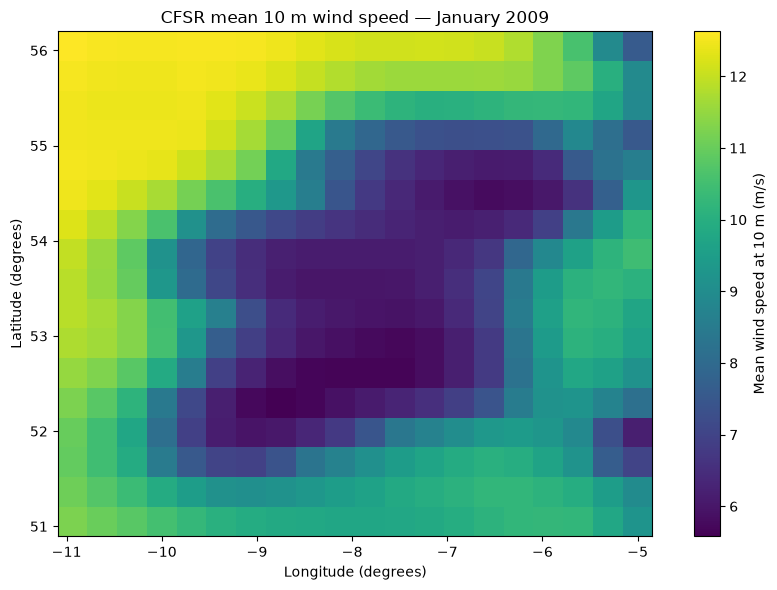

In [11]:
import matplotlib.pyplot as plt

# Calculate the mean wind speed over all January hours at each grid cell.
mean_wind = ds["wind_speed_10m"].mean(dim="time")

# Create a figure for the spatial field.
fig, ax = plt.subplots(figsize=(9, 6))

# Plot the grid-cell mean wind speed using the geographic coordinates.
mesh = ax.pcolormesh(
    ds["longitude"],
    ds["latitude"],
    mean_wind,
    shading="auto"
)

# Add a colour bar with physical units.
cbar = fig.colorbar(mesh, ax=ax)
cbar.set_label("Mean wind speed at 10 m (m/s)")

# Label the geographic axes and add a title.
ax.set_xlabel("Longitude (degrees)")
ax.set_ylabel("Latitude (degrees)")
ax.set_title("CFSR mean 10 m wind speed — January 2009")

# Keep the map proportions geographically sensible.
ax.set_aspect("equal", adjustable="box")

plt.tight_layout()
plt.show()

In [12]:
# Define the reference and target heights in metres.
z_reference = 10.0
z_hub = 80.0

# Define the power-law exponent used in the paper.
alpha = 1.0 / 7.0

# Calculate the height-extrapolation multiplier.
height_factor = (z_hub / z_reference) ** alpha

# Apply the power law to the wind-speed magnitude at every time and grid cell.
ds["wind_speed_80m"] = ds["wind_speed_10m"] * height_factor

# Attach metadata documenting the calculation.
ds["wind_speed_80m"].attrs = {
    "long_name": "Extrapolated wind speed at 80 m",
    "units": "m s-1",
    "reference_height": "10 m",
    "target_height": "80 m",
    "power_law_exponent": alpha,
}

# Print the extrapolation factor and basic statistics.
print(f"Height extrapolation factor: {height_factor:.6f}")
print(
    "Mean 10 m wind speed:",
    f"{float(ds['wind_speed_10m'].mean()):.3f} m/s"
)
print(
    "Mean 80 m wind speed:",
    f"{float(ds['wind_speed_80m'].mean()):.3f} m/s"
)
print(
    "Maximum 80 m wind speed:",
    f"{float(ds['wind_speed_80m'].max()):.3f} m/s"
)

Height extrapolation factor: 1.345900
Mean 10 m wind speed: 9.134 m/s
Mean 80 m wind speed: 12.293 m/s
Maximum 80 m wind speed: 43.957 m/s


In [18]:
def turbine_power_kw(wind_speed):
    """
    Composite 1 MW turbine power curve.

    Input:
        Wind speed in m/s.

    Output:
        Electrical power in kW.
    """

    # Convert input to a floating-point NumPy array.
    wind_speed = np.asarray(wind_speed, dtype=float)

    # Initialise power to zero outside the operating region.
    power = np.zeros_like(wind_speed)

    # Identify the polynomial operating region.
    polynomial_region = (
        (wind_speed >= 3.0002) &
        (wind_speed <= 12.9944)
    )

    # Extract wind speeds within the polynomial region.
    u = wind_speed[polynomial_region]

    # Evaluate the fitted fifth-order polynomial.
    polynomial_power = (
        0.0015 * u**5
        - 0.1967 * u**4
        + 4.0058 * u**3
        - 19.268 * u**2
        + 43.607 * u
        - 50.0
    )

    # Enforce the physical output range of the turbine.
    power[polynomial_region] = np.clip(
        polynomial_power,
        0.0,
        1000.0
    )

    # Identify the rated-power operating region.
    rated_region = (
        (wind_speed > 12.9944) &
        (wind_speed <= 25.0)
    )

    # Set output equal to rated power in this region.
    power[rated_region] = 1000.0

    return power

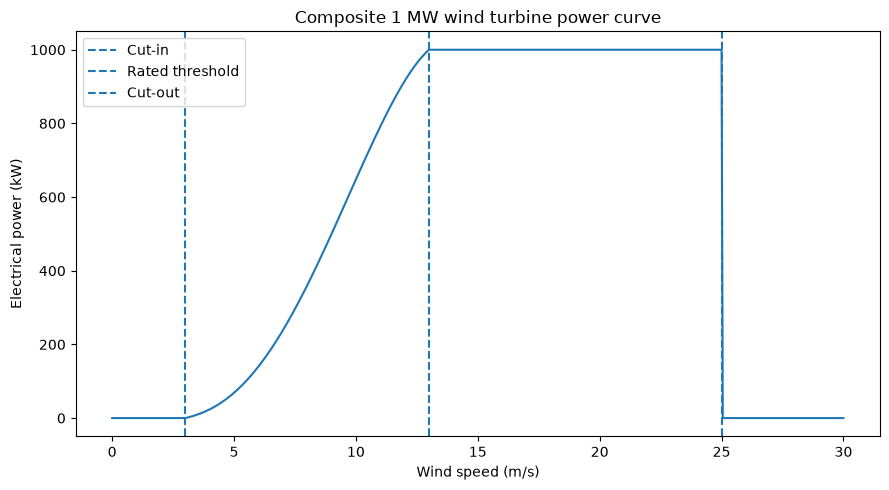

In [19]:
import matplotlib.pyplot as plt

# Define a range of wind speeds covering the operating curve.
test_speeds = np.linspace(0, 30, 601)

# Evaluate the turbine power curve at those speeds.
test_power = turbine_power_kw(test_speeds)

# Plot the resulting power curve.
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(test_speeds, test_power)

# Mark the cut-in, rated and cut-out thresholds.
ax.axvline(3.0002, linestyle="--", label="Cut-in")
ax.axvline(12.9944, linestyle="--", label="Rated threshold")
ax.axvline(25.0, linestyle="--", label="Cut-out")

# Label the axes and title.
ax.set_xlabel("Wind speed (m/s)")
ax.set_ylabel("Electrical power (kW)")
ax.set_title("Composite 1 MW wind turbine power curve")

# Show the operating thresholds.
ax.legend()

plt.tight_layout()
plt.show()

In [20]:
# Apply the turbine power curve to the 80 m wind-speed field.
ds["power_80m_kw"] = xr.apply_ufunc(
    turbine_power_kw,
    ds["wind_speed_80m"]
)

# Convert the power output into a dimensionless capacity factor.
ds["capacity_factor"] = ds["power_80m_kw"] / 1000.0

# Add descriptive metadata to the new variables.
ds["power_80m_kw"].attrs = {
    "long_name": "Composite turbine power output",
    "units": "kW",
    "rated_power": "1000 kW",
}

ds["capacity_factor"].attrs = {
    "long_name": "Normalised wind turbine capacity factor",
    "units": "1",
}

# Calculate the mean capacity factor across all hours and grid cells.
mean_cf = float(ds["capacity_factor"].mean())

# Report the resulting mean and range.
print(f"Mean grid-cell capacity factor: {mean_cf:.4f}")
print(f"Minimum capacity factor: {float(ds['capacity_factor'].min()):.4f}")
print(f"Maximum capacity factor: {float(ds['capacity_factor'].max()):.4f}")

Mean grid-cell capacity factor: 0.6165
Minimum capacity factor: 0.0000
Maximum capacity factor: 1.0000


In [21]:
from pathlib import Path
import pandas as pd

# Define the project directory.
project_dir = Path.home() / "Projects" / "Wind_curtailment_data"

# Create a dedicated directory for the paper's spatial metadata.
spatial_dir = project_dir / "spatial_metadata"
spatial_dir.mkdir(parents=True, exist_ok=True)

# Create an empty table with the fields we need to recover.
nodes = pd.DataFrame({
    "node_id": pd.Series(dtype="int64"),
    "latitude": pd.Series(dtype="float64"),
    "longitude": pd.Series(dtype="float64"),
    "region": pd.Series(dtype="str"),
    "capacity_weight": pd.Series(dtype="float64"),
})

# Save the empty template so that the spatial data has a defined schema.
nodes.to_csv(spatial_dir / "mckenna_51_nodes.csv", index=False)

print(f"Spatial metadata template saved in: {spatial_dir}")
print(nodes.dtypes)

Spatial metadata template saved in: /home/giulio/Projects/Wind_curtailment_data/spatial_metadata
node_id              int64
latitude           float64
longitude          float64
region                 str
capacity_weight    float64
dtype: object


TURBINE CURVE VALIDATION
-----------------------
Negative power values: 0
Values above rated power: 0
Capacity factors outside [0, 1]: 0

Selected operating points:
 Wind speed (m/s)  Power (kW)  Capacity factor
           0.0000    0.000000     0.000000e+00
           2.5000    0.000000     0.000000e+00
           3.0002    0.000504     5.041627e-07
           5.0000   68.810000     6.881000e-02
          10.0000  648.070000     6.480700e-01
          12.9944 1000.000000     1.000000e+00
          13.0000 1000.000000     1.000000e+00
          25.0000 1000.000000     1.000000e+00
          25.0100    0.000000     0.000000e+00
          30.0000    0.000000     0.000000e+00


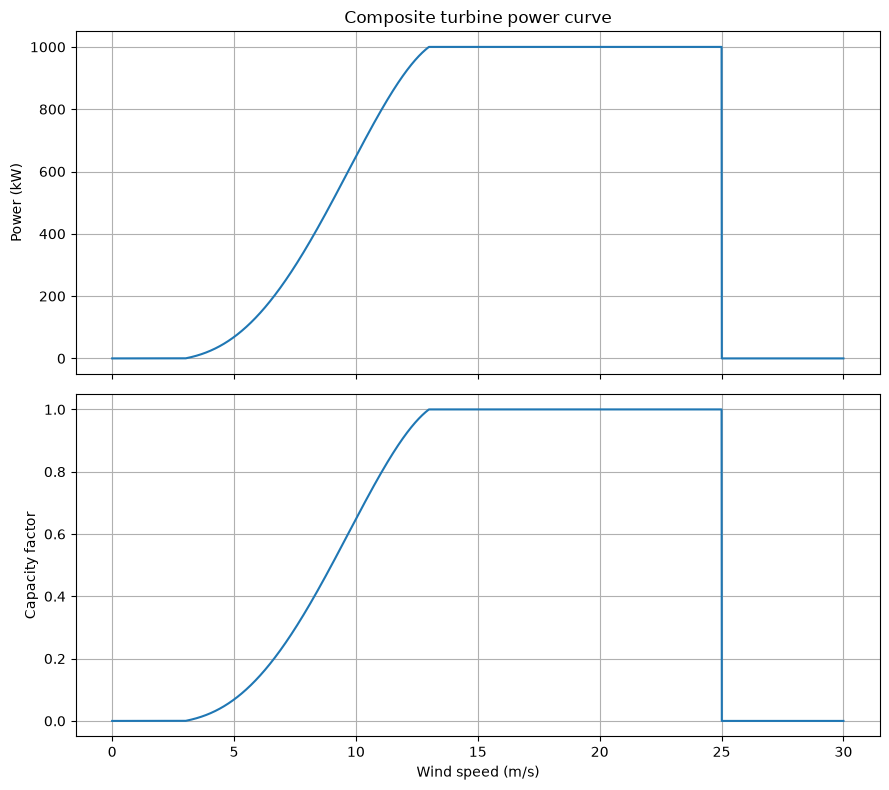

In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# 1. Evaluate the turbine curve over a dense wind-speed grid
# ---------------------------------------------------------

# Generate wind speeds from zero to 30 m/s.
test_speeds = np.linspace(0.0, 30.0, 3001)

# Evaluate the previously defined turbine power function.
test_power = turbine_power_kw(test_speeds)

# Convert power to capacity factor.
test_cf = test_power / 1000.0

# ---------------------------------------------------------
# 2. Check physical and numerical constraints
# ---------------------------------------------------------

# Check whether any power values are negative.
negative_power_count = np.sum(test_power < -1e-8)

# Check whether power exceeds the turbine's rated output.
above_rated_count = np.sum(test_power > 1000.0 + 1e-8)

# Check whether capacity factors lie within the physical range.
outside_cf_count = np.sum(
    (test_cf < -1e-8) | (test_cf > 1.0 + 1e-8)
)

# Print the diagnostic results.
print("TURBINE CURVE VALIDATION")
print("-----------------------")
print(f"Negative power values: {negative_power_count}")
print(f"Values above rated power: {above_rated_count}")
print(f"Capacity factors outside [0, 1]: {outside_cf_count}")

# ---------------------------------------------------------
# 3. Inspect important operating points
# ---------------------------------------------------------

# Define the wind speeds at important turbine thresholds.
threshold_speeds = np.array([
    0.0,
    2.5,
    3.0002,
    5.0,
    10.0,
    12.9944,
    13.0,
    25.0,
    25.01,
    30.0
])

# Evaluate the power curve at these selected speeds.
threshold_power = turbine_power_kw(threshold_speeds)

# Display the results in a readable table.
threshold_table = pd.DataFrame({
    "Wind speed (m/s)": threshold_speeds,
    "Power (kW)": threshold_power,
    "Capacity factor": threshold_power / 1000.0
})

print("\nSelected operating points:")
print(threshold_table.to_string(index=False))

# ---------------------------------------------------------
# 4. Plot power and capacity factor
# ---------------------------------------------------------

# Create separate plots for power and capacity factor.
fig, axes = plt.subplots(2, 1, figsize=(9, 8), sharex=True)

# Plot electrical power.
axes[0].plot(test_speeds, test_power)
axes[0].set_ylabel("Power (kW)")
axes[0].set_title("Composite turbine power curve")
axes[0].grid(True)

# Plot normalised capacity factor.
axes[1].plot(test_speeds, test_cf)
axes[1].set_xlabel("Wind speed (m/s)")
axes[1].set_ylabel("Capacity factor")
axes[1].set_ylim(-0.05, 1.05)
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [23]:
# Apply the corrected turbine power curve to the 80 m wind field.
ds["power_80m_kw"] = xr.apply_ufunc(
    turbine_power_kw,
    ds["wind_speed_80m"]
)

# Convert power into a dimensionless capacity factor.
ds["capacity_factor"] = ds["power_80m_kw"] / 1000.0

# Calculate the mean capacity factor over the entire grid and month.
mean_cf = float(ds["capacity_factor"].mean())

# Calculate the median capacity factor.
median_cf = float(ds["capacity_factor"].median())

# Calculate the fraction of observations at zero output.
zero_fraction = float(
    (ds["capacity_factor"] == 0).mean()
)

# Calculate the fraction of observations at rated output.
rated_fraction = float(
    (ds["capacity_factor"] == 1).mean()
)

# Calculate the fraction of observations in partial-load operation.
partial_fraction = float(
    (
        (ds["capacity_factor"] > 0) &
        (ds["capacity_factor"] < 1)
    ).mean()
)

# Display the results.
print("JANUARY 2009 CAPACITY FACTOR STATISTICS")
print("---------------------------------------")
print(f"Mean capacity factor: {mean_cf:.4f}")
print(f"Median capacity factor: {median_cf:.4f}")
print(f"Zero-output fraction: {zero_fraction:.2%}")
print(f"Partial-load fraction: {partial_fraction:.2%}")
print(f"Rated-output fraction: {rated_fraction:.2%}")

JANUARY 2009 CAPACITY FACTOR STATISTICS
---------------------------------------
Mean capacity factor: 0.6165
Median capacity factor: 0.7677
Zero-output fraction: 7.19%
Partial-load fraction: 54.01%
Rated-output fraction: 38.80%


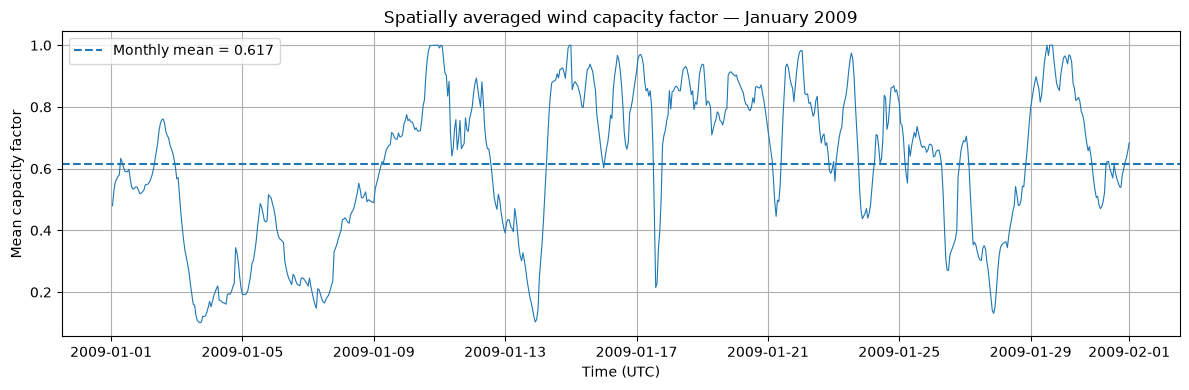

In [24]:
# Average capacity factor across all grid cells at each hour.
hourly_mean_cf = ds["capacity_factor"].mean(
    dim=("y", "x")
)

# Create a figure for the hourly time series.
fig, ax = plt.subplots(figsize=(12, 4))

# Plot the hourly spatially averaged capacity factor.
ax.plot(
    hourly_mean_cf["time"],
    hourly_mean_cf,
    linewidth=0.8
)

# Add axis labels and title.
ax.set_xlabel("Time (UTC)")
ax.set_ylabel("Mean capacity factor")
ax.set_title("Spatially averaged wind capacity factor — January 2009")

# Display a horizontal reference line at the monthly mean.
ax.axhline(
    mean_cf,
    linestyle="--",
    label=f"Monthly mean = {mean_cf:.3f}"
)

ax.legend()
ax.grid(True)

plt.tight_layout()
plt.show()

In [26]:
import numpy as np
import pandas as pd
import geopandas as gpd
import xarray as xr
import matplotlib.pyplot as plt

from pathlib import Path
from cartopy.io import shapereader
from shapely.geometry import Point, Polygon, box
from shapely.ops import transform
from pyproj import Transformer

# ---------------------------------------------------------
# 1. Retrieve the Natural Earth 1:10m land dataset
# ---------------------------------------------------------

# Obtain the local path to the Natural Earth land shapefile.
land_shapefile = shapereader.natural_earth(
    resolution="10m",
    category="physical",
    name="land"
)

# Read the geographic land geometries.
land_reader = shapereader.Reader(land_shapefile)

# Define a point well inside the island of Ireland.
# This is used to identify the correct land polygon.
ireland_reference_point = Point(-8.0, 53.5)

# Find the land polygon containing the reference point.
ireland_candidates = []

for record in land_reader.records():

    # Extract the geometry from the current Natural Earth record.
    geometry = record.geometry

    # A record may contain multiple separate polygons.
    if geometry.geom_type == "Polygon":
        polygons = [geometry]
    else:
        polygons = list(geometry.geoms)

    # Retain the polygon containing our reference point.
    for polygon in polygons:
        if polygon.covers(ireland_reference_point):
            ireland_candidates.append(polygon)

# Ensure that exactly one main-island polygon was identified.
if len(ireland_candidates) != 1:
    raise RuntimeError(
        f"Expected one Ireland polygon, found {len(ireland_candidates)}."
    )

# Store the main island polygon.
ireland_geom = ireland_candidates[0]

print("Ireland polygon successfully identified.")
print("Geometry type:", ireland_geom.geom_type)
print("Geographic bounds:", ireland_geom.bounds)

/home/giulio/.local/lib/python3.13/site-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/10m_physical/ne_10m_land.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


Ireland polygon successfully identified.
Geometry type: Polygon
Geographic bounds: (-10.478179490999935, 51.44570547100005, -5.430775519999941, 55.386379299000055)


In [27]:
import rasterio

# Reopen the original CFSR GeoTIFF to retrieve its affine transform.
with rasterio.open(file_path) as src:

    # Retrieve the raster dimensions.
    height = src.height
    width = src.width

    # Retrieve the affine transformation from pixel to geographic coordinates.
    raster_transform = src.transform

# Create an empty list for the grid-cell polygons.
cell_polygons = []

# Loop over every raster row.
for row in range(height):

    # Loop over every raster column.
    for col in range(width):

        # Calculate the geographic coordinates of the cell's four corners.
        x_left, y_top = raster_transform * (col, row)
        x_right, y_bottom = raster_transform * (col + 1, row + 1)

        # Construct the rectangular grid-cell polygon.
        cell_polygon = Polygon([
            (x_left, y_top),
            (x_right, y_top),
            (x_right, y_bottom),
            (x_left, y_bottom)
        ])

        # Store the cell identifier and its geographic geometry.
        cell_polygons.append({
            "row": row,
            "col": col,
            "cell_id": row * width + col,
            "geometry": cell_polygon
        })

# Convert the grid-cell records into a GeoDataFrame.
cells_gdf = gpd.GeoDataFrame(
    cell_polygons,
    geometry="geometry",
    crs="EPSG:4326"
)

print(f"Created {len(cells_gdf)} grid-cell polygons.")

Created 340 grid-cell polygons.


In [28]:
# Define the equal-area coordinate reference system.
equal_area_crs = "EPSG:3035"

# Transform the Ireland polygon into the equal-area CRS.
ireland_equal_area = (
    gpd.GeoSeries([ireland_geom], crs="EPSG:4326")
    .to_crs(equal_area_crs)
    .iloc[0]
)

# Transform all CFSR grid cells into the same equal-area CRS.
cells_equal_area = cells_gdf.to_crs(equal_area_crs)

# Calculate the total area of each grid cell in square metres.
cells_gdf["cell_area_m2"] = cells_equal_area.geometry.area.values

# Calculate the area of each grid cell that intersects Ireland.
cells_gdf["land_area_m2"] = [
    geometry.intersection(ireland_equal_area).area
    for geometry in cells_equal_area.geometry
]

# Calculate the fraction of each grid cell covered by Ireland.
cells_gdf["land_fraction"] = (
    cells_gdf["land_area_m2"] / cells_gdf["cell_area_m2"]
)

# Protect against tiny floating-point excursions outside [0, 1].
cells_gdf["land_fraction"] = cells_gdf["land_fraction"].clip(0.0, 1.0)

# Report the number of cells with any Irish land coverage.
land_cells = cells_gdf[cells_gdf["land_fraction"] > 0]

print(f"Total grid cells: {len(cells_gdf)}")
print(f"Cells intersecting Ireland: {len(land_cells)}")
print(f"Fully land-covered cells: {(cells_gdf['land_fraction'] >= 0.999).sum()}")
print(f"Partially land-covered cells: {((cells_gdf['land_fraction'] > 0) & (cells_gdf['land_fraction'] < 0.999)).sum()}")
print(f"Total represented land area: {cells_gdf['land_area_m2'].sum() / 1e6:.1f} km²")

Total grid cells: 340
Cells intersecting Ireland: 159
Fully land-covered cells: 71
Partially land-covered cells: 88
Total represented land area: 83415.8 km²


In [29]:
# Convert the one-dimensional cell table into two-dimensional grid arrays.
land_fraction = (
    cells_gdf
    .sort_values(["row", "col"])["land_fraction"]
    .to_numpy()
    .reshape(height, width)
)

land_area = (
    cells_gdf
    .sort_values(["row", "col"])["land_area_m2"]
    .to_numpy()
    .reshape(height, width)
)

# Attach the fractional land coverage to the meteorological dataset.
ds["land_fraction"] = xr.DataArray(
    land_fraction,
    dims=("y", "x"),
    coords={"y": np.arange(height), "x": np.arange(width)},
    attrs={
        "long_name": "Fraction of grid cell covered by the island of Ireland",
        "units": "1"
    }
)

# Attach the land area in square metres.
ds["land_area_m2"] = xr.DataArray(
    land_area,
    dims=("y", "x"),
    coords={"y": np.arange(height), "x": np.arange(width)},
    attrs={
        "long_name": "Irish land area represented by grid cell",
        "units": "m2"
    }
)

# Calculate the normalised land-area weight for every cell.
ds["land_weight"] = (
    ds["land_area_m2"] / ds["land_area_m2"].sum()
)

print("Sum of land weights:", float(ds["land_weight"].sum()))

Sum of land weights: 1.0


In [30]:
# Calculate the land-area-weighted capacity factor at each hour.
ds["capacity_factor_land_weighted"] = (
    ds["capacity_factor"] * ds["land_weight"]
).sum(dim=("y", "x"))

# Calculate the monthly mean of the land-area-weighted time series.
land_weighted_monthly_cf = float(
    ds["capacity_factor_land_weighted"].mean(dim="time")
)

# Calculate the unweighted grid-cell mean for comparison.
unweighted_monthly_cf = float(
    ds["capacity_factor"].mean(dim=("y", "x", "time"))
)

# Report both values.
print("SPATIAL AGGREGATION COMPARISON")
print("-----------------------------")
print(f"Equal weighting of all grid cells: {unweighted_monthly_cf:.4f}")
print(f"Irish land-area weighting:         {land_weighted_monthly_cf:.4f}")
print(
    "Difference (percentage points):   "
    f"{100 * (land_weighted_monthly_cf - unweighted_monthly_cf):+.2f}"
)

SPATIAL AGGREGATION COMPARISON
-----------------------------
Equal weighting of all grid cells: 0.6165
Irish land-area weighting:         0.4630
Difference (percentage points):   -15.36


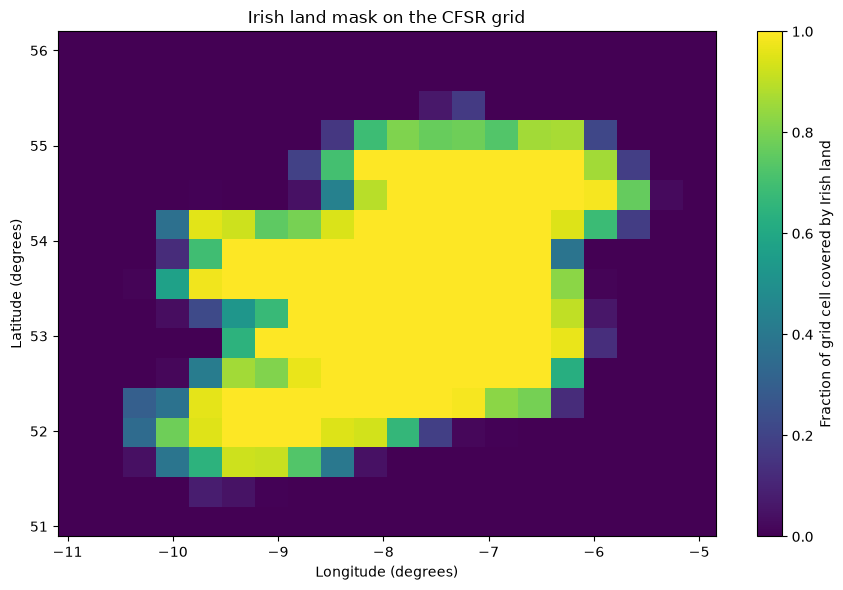

In [31]:
# Create a figure showing fractional land coverage.
fig, ax = plt.subplots(figsize=(9, 6))

# Plot the fraction of each grid cell covered by Irish land.
mesh = ax.pcolormesh(
    ds["longitude"],
    ds["latitude"],
    ds["land_fraction"],
    shading="auto",
    vmin=0,
    vmax=1
)

# Add a colour bar showing fractional coverage.
cbar = fig.colorbar(mesh, ax=ax)
cbar.set_label("Fraction of grid cell covered by Irish land")

# Label the geographic axes.
ax.set_xlabel("Longitude (degrees)")
ax.set_ylabel("Latitude (degrees)")
ax.set_title("Irish land mask on the CFSR grid")

# Display the plot.
plt.tight_layout()
plt.show()

In [32]:
# Confirm that the land fractions are physically valid.
assert np.all(ds["land_fraction"].values >= 0.0)
assert np.all(ds["land_fraction"].values <= 1.0)

# Confirm that the normalized land weights sum to one.
weight_sum = float(ds["land_weight"].sum())
assert np.isclose(weight_sum, 1.0, atol=1e-10)

# Confirm that the weighted hourly capacity factors remain physical.
hourly_land_cf = ds["capacity_factor_land_weighted"].values
assert np.all(np.isfinite(hourly_land_cf))
assert np.all(hourly_land_cf >= 0.0)
assert np.all(hourly_land_cf <= 1.0)

# Summarize the hourly national-land proxy time series.
print("LAND-WEIGHTED TIME-SERIES DIAGNOSTICS")
print("------------------------------------")
print(f"Weight sum:       {weight_sum:.12f}")
print(f"Hourly minimum:   {hourly_land_cf.min():.4f}")
print(f"Hourly maximum:   {hourly_land_cf.max():.4f}")
print(f"Hourly mean:      {hourly_land_cf.mean():.4f}")
print(f"Hourly std. dev.: {hourly_land_cf.std():.4f}")
print(f"Number of hours:  {hourly_land_cf.size}")

LAND-WEIGHTED TIME-SERIES DIAGNOSTICS
------------------------------------
Weight sum:       1.000000000000
Hourly minimum:   0.0110
Hourly maximum:   1.0000
Hourly mean:      0.4630
Hourly std. dev.: 0.3353
Number of hours:  744


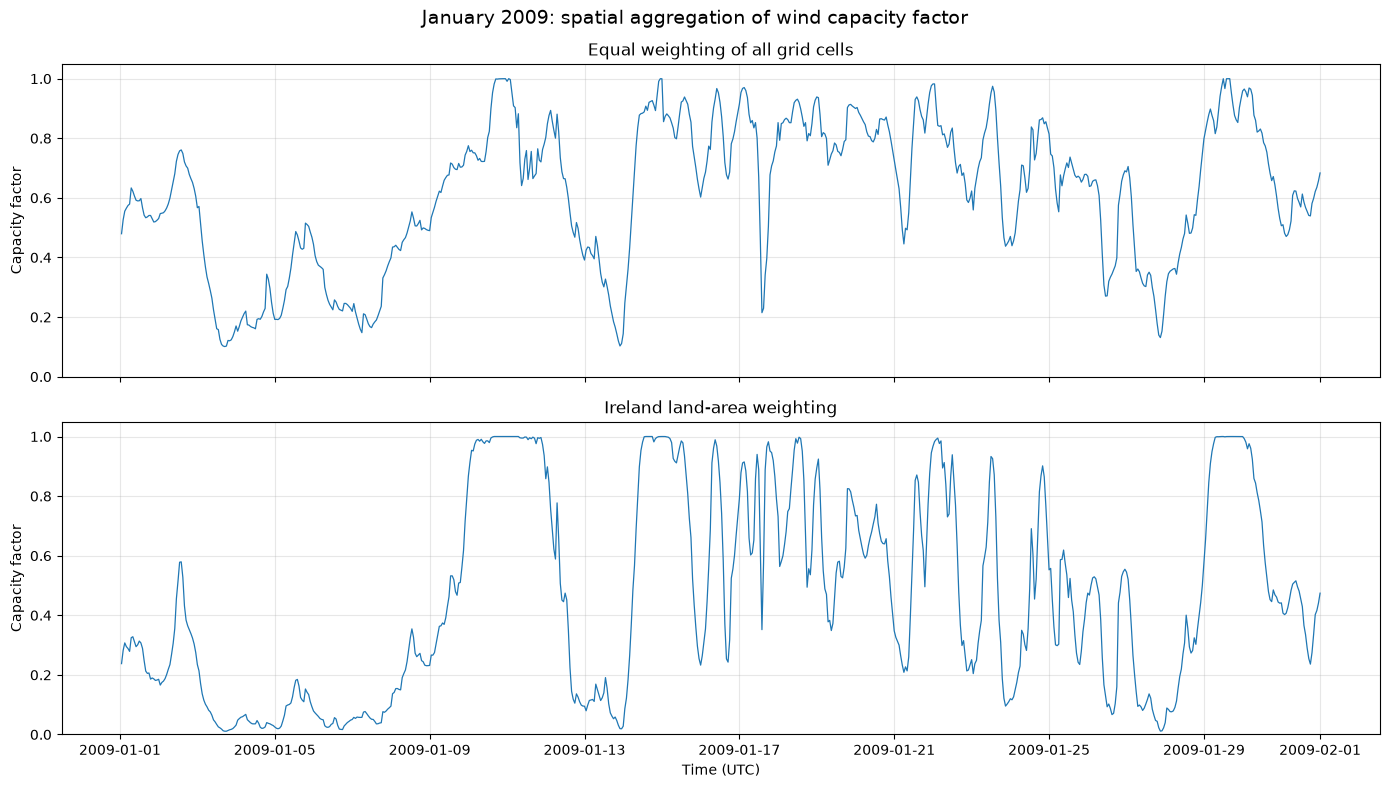

In [33]:
# Calculate the hourly mean across all 340 grid cells.
# This is the original equal-grid-cell aggregation.
ds["capacity_factor_unweighted"] = (
    ds["capacity_factor"].mean(dim=("y", "x"))
)

# Extract both hourly time series as NumPy arrays for plotting.
unweighted_hourly = ds["capacity_factor_unweighted"].values
land_weighted_hourly = ds["capacity_factor_land_weighted"].values

# Create a figure with two vertically aligned panels.
fig, axes = plt.subplots(
    2, 1,
    figsize=(14, 8),
    sharex=True
)

# Plot the equal-grid-cell time series.
axes[0].plot(
    timestamps,
    unweighted_hourly,
    linewidth=0.9
)
axes[0].set_ylabel("Capacity factor")
axes[0].set_title("Equal weighting of all grid cells")
axes[0].set_ylim(0, 1.05)
axes[0].grid(True, alpha=0.3)

# Plot the Ireland land-area-weighted time series.
axes[1].plot(
    timestamps,
    land_weighted_hourly,
    linewidth=0.9
)
axes[1].set_ylabel("Capacity factor")
axes[1].set_title("Ireland land-area weighting")
axes[1].set_ylim(0, 1.05)
axes[1].set_xlabel("Time (UTC)")
axes[1].grid(True, alpha=0.3)

# Add an overall title and adjust spacing.
fig.suptitle(
    "January 2009: spatial aggregation of wind capacity factor",
    fontsize=14
)
fig.tight_layout()

# Display the comparison.
plt.show()

In [34]:
# Calculate the Pearson correlation between the two hourly profiles.
profile_correlation = np.corrcoef(
    unweighted_hourly,
    land_weighted_hourly
)[0, 1]

# Calculate the mean absolute difference between the profiles.
mean_absolute_difference = np.mean(
    np.abs(unweighted_hourly - land_weighted_hourly)
)

# Report the temporal comparison statistics.
print(f"Hourly profile correlation: {profile_correlation:.4f}")
print(
    "Mean absolute hourly difference: "
    f"{mean_absolute_difference:.4f}"
)

Hourly profile correlation: 0.8825
Mean absolute hourly difference: 0.2000


In [35]:
# Import the Cartopy shapefile reader and GeoPandas.
from cartopy.io import shapereader
import geopandas as gpd

# Download or locate Natural Earth's 10m administrative-level-1 boundaries.
admin1_path = shapereader.natural_earth(
    resolution="10m",
    category="cultural",
    name="admin_1_states_provinces"
)

# Read the administrative boundaries into a GeoDataFrame.
admin1 = gpd.read_file(admin1_path)

# Inspect the available columns so we can identify country and county fields.
print("Available boundary attributes:")
print(admin1.columns.tolist())

# Find records whose country name or administrative name refers to Ireland.
# This is an inspection step; we will verify the actual field names first.
print("\nExample records:")
print(admin1.head(3).T)

/home/giulio/.local/lib/python3.13/site-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/10m_cultural/ne_10m_admin_1_states_provinces.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


Available boundary attributes:
['featurecla', 'scalerank', 'adm1_code', 'diss_me', 'iso_3166_2', 'wikipedia', 'iso_a2', 'adm0_sr', 'name', 'name_alt', 'name_local', 'type', 'type_en', 'code_local', 'code_hasc', 'note', 'hasc_maybe', 'region', 'region_cod', 'provnum_ne', 'gadm_level', 'check_me', 'datarank', 'abbrev', 'postal', 'area_sqkm', 'sameascity', 'labelrank', 'name_len', 'mapcolor9', 'mapcolor13', 'fips', 'fips_alt', 'woe_id', 'woe_label', 'woe_name', 'latitude', 'longitude', 'sov_a3', 'adm0_a3', 'adm0_label', 'admin', 'geonunit', 'gu_a3', 'gn_id', 'gn_name', 'gns_id', 'gns_name', 'gn_level', 'gn_region', 'gn_a1_code', 'region_sub', 'sub_code', 'gns_level', 'gns_lang', 'gns_adm1', 'gns_region', 'min_label', 'max_label', 'min_zoom', 'wikidataid', 'name_ar', 'name_bn', 'name_de', 'name_en', 'name_es', 'name_fr', 'name_el', 'name_hi', 'name_hu', 'name_id', 'name_it', 'name_ja', 'name_ko', 'name_nl', 'name_pl', 'name_pt', 'name_ru', 'name_sv', 'name_tr', 'name_vi', 'name_zh', 'ne_id

In [36]:
# Select administrative units belonging to Ireland.
ireland_admin1 = admin1[
    admin1["admin"].isin(["Ireland", "United Kingdom"])
].copy()

# Display the names and associated countries for inspection.
print(
    ireland_admin1[["admin", "name"]]
    .sort_values(["admin", "name"])
    .to_string(index=False)
)

         admin                                    name
       Ireland                                  Carlow
       Ireland                                   Cavan
       Ireland                                   Clare
       Ireland                                    Cork
       Ireland                                    Cork
       Ireland                                 Donegal
       Ireland                                  Dublin
       Ireland                  Dún Laoghaire–Rathdown
       Ireland                                  Fingal
       Ireland                                  Galway
       Ireland                                  Galway
       Ireland                                   Kerry
       Ireland                                 Kildare
       Ireland                                Kilkenny
       Ireland                                Laoighis
       Ireland                                 Leitrim
       Ireland                                Limerick
       Ire

In [38]:
# Map Republic of Ireland administrative names to traditional provinces.
# Duplicate county names are intentionally assigned to the same province.
republic_province = {
    # Connacht
    "Galway": "Connacht",
    "Leitrim": "Connacht",
    "Mayo": "Connacht",
    "Roscommon": "Connacht",
    "Sligo": "Connacht",

    # Leinster
    "Carlow": "Leinster",
    "Dublin": "Leinster",
    "Dún Laoghaire–Rathdown": "Leinster",
    "Fingal": "Leinster",
    "South Dublin": "Leinster",
    "Kildare": "Leinster",
    "Kilkenny": "Leinster",
    "Laoighis": "Leinster",
    "Longford": "Leinster",
    "Louth": "Leinster",
    "Meath": "Leinster",
    "Offaly": "Leinster",
    "Westmeath": "Leinster",
    "Wexford": "Leinster",
    "Wicklow": "Leinster",

    # Munster
    "Clare": "Munster",
    "Cork": "Munster",
    "Kerry": "Munster",
    "Limerick": "Munster",
    "North Tipperary": "Munster",
    "South Tipperary": "Munster",
    "Waterford": "Munster",

    # Ulster: counties in the Republic
    "Cavan": "Ulster",
    "Donegal": "Ulster",
    "Monaghan": "Ulster",
}

# Copy the geographic dataset so we do not modify the original.
province_units = island_admin1.copy()

# Assign all Northern Ireland administrative districts to Ulster.
province_units.loc[
    province_units["admin"] == "United Kingdom",
    "province"
] = "Ulster"

# Assign Republic administrative units using the explicit mapping.
republic_mask = province_units["admin"] == "Ireland"

province_units.loc[republic_mask, "province"] = (
    province_units.loc[republic_mask, "name"]
    .map(republic_province)
)

# Check that every administrative unit received a province.
unassigned = province_units[province_units["province"].isna()]

print("Unassigned administrative units:")
print(unassigned[["admin", "name"]].to_string(index=False))

# Stop if any administrative unit was missed.
assert unassigned.empty, "Some administrative units have no province assignment."

Unassigned administrative units:
Empty DataFrame
Columns: [admin, name]
Index: []


In [39]:
# Repair invalid geometries before dissolving, if necessary.
# buffer(0) is a common fallback for simple polygon validity problems.
province_units["geometry"] = province_units.geometry.apply(
    lambda geom: geom if geom.is_valid else geom.buffer(0)
)

# Dissolve all administrative units assigned to the same province.
# The union operation prevents shared or overlapping boundaries
# from being counted more than once within each province.
provinces = province_units.dissolve(
    by="province",
    as_index=False
)

# Reproject to an equal-area coordinate reference system for area calculations.
provinces = provinces.to_crs("EPSG:3035")

# Calculate each province's geographic area in square kilometres.
provinces["area_km2"] = provinces.geometry.area / 1e6

# Display the four resulting province areas.
print(
    provinces[["province", "area_km2"]]
    .sort_values("province")
    .to_string(index=False)
)

# Confirm that the result contains exactly four provinces.
assert set(provinces["province"]) == {
    "Connacht", "Leinster", "Munster", "Ulster"
}

province     area_km2
Connacht 17591.629606
Leinster 19749.157231
 Munster 24147.075299
  Ulster 22208.474526


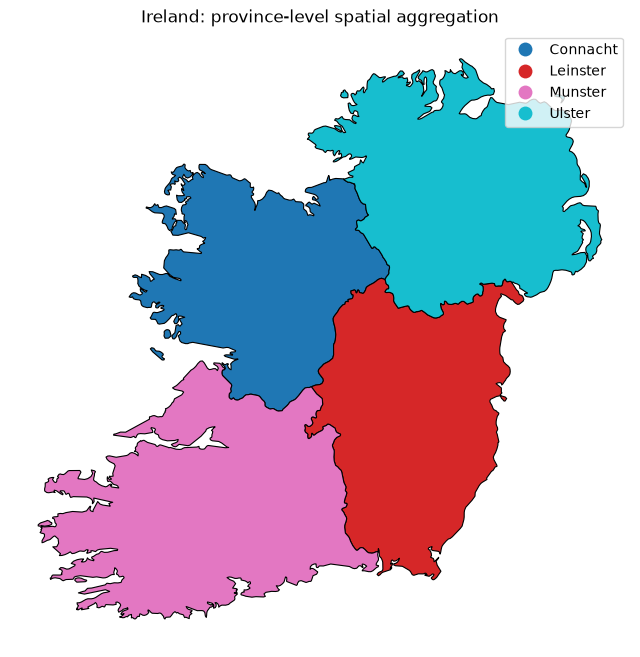

In [40]:
# Create a figure for the four dissolved province geometries.
fig, ax = plt.subplots(figsize=(8, 10))

# Draw each province with its name as the legend category.
provinces.plot(
    ax=ax,
    column="province",
    legend=True,
    edgecolor="black",
    linewidth=0.8
)

# Add a title and remove unnecessary plot axes.
ax.set_title("Ireland: province-level spatial aggregation")
ax.set_axis_off()

# Display the map.
plt.show()

In [41]:
# Reconstruct the CFSR grid-cell polygons from the raster transform.
# This uses the same raster transform and dimensions as the original TIFF.
grid_cells = []

for row in range(ds.sizes["y"]):
    for col in range(ds.sizes["x"]):

        # Get the geographic coordinates of the cell's upper-left corner.
        x_left, y_top = raster_transform * (col, row)

        # Get the geographic coordinates of the cell's lower-right corner.
        x_right, y_bottom = raster_transform * (col + 1, row + 1)

        # Construct the rectangular cell polygon.
        cell_polygon = Polygon([
            (x_left, y_top),
            (x_right, y_top),
            (x_right, y_bottom),
            (x_left, y_bottom)
        ])

        # Store its grid indices and geometry.
        grid_cells.append({
            "row": row,
            "col": col,
            "geometry": cell_polygon
        })

# Convert the grid cells into a GeoDataFrame in geographic coordinates.
grid_gdf = gpd.GeoDataFrame(
    grid_cells,
    geometry="geometry",
    crs="EPSG:4326"
)

# Reproject grid cells into the equal-area CRS used for the provinces.
grid_gdf = grid_gdf.to_crs("EPSG:3035")

# Ensure provinces and grid cells use the same CRS.
provinces = provinces.to_crs("EPSG:3035")

# Calculate the full area of every grid cell in square metres.
grid_gdf["cell_area_m2"] = grid_gdf.geometry.area

# Create a record for every grid-cell/province intersection.
intersection_records = []

for _, province in provinces.iterrows():

    # Identify the province name and its geometry.
    province_name = province["province"]
    province_geometry = province.geometry

    # Loop over grid cells and calculate their overlap with this province.
    for _, cell in grid_gdf.iterrows():

        # Calculate the geometric intersection.
        intersection = cell.geometry.intersection(province_geometry)

        # Only retain intersections with positive area.
        if not intersection.is_empty and intersection.area > 0:

            intersection_records.append({
                "row": cell["row"],
                "col": cell["col"],
                "province": province_name,
                "intersection_area_m2": intersection.area,
                "cell_area_m2": cell["cell_area_m2"]
            })

# Convert the intersection records into a DataFrame.
province_intersections = pd.DataFrame(intersection_records)

# Calculate the fraction of each grid cell belonging to each province.
province_intersections["cell_fraction"] = (
    province_intersections["intersection_area_m2"] /
    province_intersections["cell_area_m2"]
)

# Report the number of grid-cell/province intersections.
print("Number of grid-cell/province intersections:",
      len(province_intersections))

# Display the number of intersecting cells for each province.
print("\nIntersecting cells by province:")
print(
    province_intersections.groupby("province")["row"]
    .count()
    .sort_index()
)

# Confirm that no individual cell is assigned more than 100% of its area.
cell_fraction_sums = province_intersections.groupby(
    ["row", "col"]
)["cell_fraction"].sum()

print("\nMaximum summed province fraction for any cell:",
      cell_fraction_sums.max())

Number of grid-cell/province intersections: 198

Intersecting cells by province:
province
Connacht    46
Leinster    45
Munster     57
Ulster      50
Name: row, dtype: int64

Maximum summed province fraction for any cell: 1.0000000000000056


In [42]:
# Create a dictionary to hold one hourly capacity-factor series per province.
regional_capacity_factors = {}

# Process each province independently.
for province_name in provinces["province"]:

    # Select all grid-cell intersections belonging to this province.
    province_data = province_intersections[
        province_intersections["province"] == province_name
    ].copy()

    # Extract the row and column indices of the contributing grid cells.
    rows = province_data["row"].to_numpy(dtype=int)
    cols = province_data["col"].to_numpy(dtype=int)

    # Extract the intersection areas in square metres.
    areas = province_data["intersection_area_m2"].to_numpy()

    # Extract the capacity-factor values for those grid cells and all hours.
    # The resulting array has dimensions (time, intersecting cells).
    cell_cf = ds["capacity_factor"].values[:, rows, cols]

    # Calculate the area-weighted mean capacity factor at every hour.
    # Each cell contributes in proportion to its area inside the province.
    regional_cf = np.average(
        cell_cf,
        axis=1,
        weights=areas
    )

    # Store the resulting hourly series, indexed by the original timestamps.
    regional_capacity_factors[province_name] = pd.Series(
        regional_cf,
        index=timestamps,
        name=province_name
    )

# Combine the four series into a single DataFrame.
regional_cf_df = pd.DataFrame(regional_capacity_factors)

# Display the first few hourly observations.
print("First five hourly regional capacity factors:")
display(regional_cf_df.head())

# Calculate descriptive statistics for each province.
print("\nRegional capacity-factor summary:")
display(
    regional_cf_df.agg(["mean", "std", "min", "max"]).T
)

First five hourly regional capacity factors:


,Connacht,Leinster,Munster,Ulster
2009-01-01 01:00:00+00:00,0.222962,0.124244,0.524174,0.043007
2009-01-01 02:00:00+00:00,0.298052,0.139578,0.599814,0.055522
2009-01-01 03:00:00+00:00,0.353193,0.146001,0.631738,0.067305
2009-01-01 04:00:00+00:00,0.351488,0.131024,0.602695,0.066764
2009-01-01 05:00:00+00:00,0.347723,0.120007,0.590311,0.069286



Regional capacity-factor summary:


,mean,std,min,max
Connacht,0.489339,0.354799,0.000788,1.0
Leinster,0.451730,0.365932,0.000000,1.0
Munster,0.442179,0.349206,0.000000,1.0
Ulster,0.477425,0.373435,0.001935,1.0


In [43]:
# Calculate the total represented land area within each province.
province_land_areas = (
    province_intersections
    .groupby("province")["intersection_area_m2"]
    .sum()
)

# Normalize the province areas to obtain spatial aggregation weights.
province_area_weights = (
    province_land_areas / province_land_areas.sum()
)

# Combine the four regional time series using their land-area weights.
reconstructed_island_cf = (
    regional_cf_df * province_area_weights
).sum(axis=1)

# Compare the reconstructed profile against the original island profile.
original_island_cf = ds["capacity_factor_land_weighted"].to_series()
original_island_cf.index = timestamps

# Calculate the maximum absolute difference across all 744 hours.
maximum_difference = np.max(
    np.abs(
        reconstructed_island_cf.values -
        original_island_cf.values
    )
)

# Report the numerical reconstruction error.
print(
    "Maximum absolute reconstruction difference:",
    f"{maximum_difference:.12e}"
)

# Require agreement within a tight numerical tolerance.
assert np.allclose(
    reconstructed_island_cf.values,
    original_island_cf.values,
    atol=1e-10,
    rtol=1e-10
), "Regional profiles do not reconstruct the original island profile."

Maximum absolute reconstruction difference: 2.687301892174e-03


AssertionError: Regional profiles do not reconstruct the original island profile.

In [44]:
# Create a 2D array to accumulate the province-intersection area
# represented in each CFSR grid cell.
province_area_grid = np.zeros(
    (ds.sizes["y"], ds.sizes["x"]),
    dtype=float
)

# Add each cell's intersection area from all four provinces.
for _, record in province_intersections.iterrows():

    # Retrieve the grid-cell indices.
    row = int(record["row"])
    col = int(record["col"])

    # Add this cell's area within the current province.
    province_area_grid[row, col] += record["intersection_area_m2"]

# Extract the original land-area array used for the Ireland land mask.
original_land_area_grid = ds["land_area_m2"].values

# Calculate the total areas represented by both spatial approaches.
original_total_area = original_land_area_grid.sum()
province_total_area = province_area_grid.sum()

# Calculate the cell-by-cell area difference.
area_difference_grid = (
    province_area_grid - original_land_area_grid
)

# Report the total and maximum local differences.
print("SPATIAL MASK COMPARISON")
print("-----------------------")
print(f"Original land-mask area: {original_total_area / 1e6:.2f} km²")
print(f"Province-overlay area:   {province_total_area / 1e6:.2f} km²")
print(
    "Total area difference:   "
    f"{(province_total_area - original_total_area) / 1e6:+.2f} km²"
)
print(
    "Maximum absolute cell difference: "
    f"{np.abs(area_difference_grid).max() / 1e6:.4f} km²"
)

# Count cells where the two masks differ by more than 1 square metre.
different_cells = np.sum(np.abs(area_difference_grid) > 1.0)

print(f"Cells with differing land areas: {different_cells}")

SPATIAL MASK COMPARISON
-----------------------
Original land-mask area: 83415.83 km²
Province-overlay area:   83696.34 km²
Total area difference:   +280.51 km²
Maximum absolute cell difference: 127.7486 km²
Cells with differing land areas: 24


In [45]:
# Calculate the area-weighted combination of the four regional profiles.
# These weights are based on the actual province/grid intersections.
province_area_weights = (
    province_land_areas / province_land_areas.sum()
)

# Reconstruct the island-wide time series from the regional profiles.
reconstructed_province_cf = (
    regional_cf_df * province_area_weights
).sum(axis=1)

# Calculate the direct area-weighted capacity factor using the same
# province-overlay cell areas, without first aggregating into provinces.
cell_cf_all_hours = ds["capacity_factor"].values

# Reshape the province area grid into a vector of cell weights.
province_area_weights_grid = province_area_grid.ravel()

# Reshape capacity factors to (time, grid cells).
cell_cf_flat = cell_cf_all_hours.reshape(
    cell_cf_all_hours.shape[0], -1
)

# Calculate the direct province-overlay-weighted hourly capacity factor.
direct_province_overlay_cf = np.average(
    cell_cf_flat,
    axis=1,
    weights=province_area_weights_grid
)

# Compare the regional reconstruction with the direct calculation.
regional_reconstruction_error = np.max(
    np.abs(
        reconstructed_province_cf.values -
        direct_province_overlay_cf
    )
)

print(
    "Maximum regional reconstruction error:",
    f"{regional_reconstruction_error:.12e}"
)

Maximum regional reconstruction error: 3.330669073875e-16


In [46]:
# Calculate the total represented land area for each province.
province_land_areas = (
    province_intersections
    .groupby("province")["intersection_area_m2"]
    .sum()
)

# Normalize the province areas to obtain island-wide spatial weights.
province_area_weights = (
    province_land_areas / province_land_areas.sum()
)

# Calculate the island-wide capacity factor by combining the
# four provincial profiles using their represented land areas.
island_cf_province_geometry = (
    regional_cf_df * province_area_weights
).sum(axis=1)

# Give the resulting series an explicit, descriptive name.
island_cf_province_geometry.name = (
    "capacity_factor_island_province_geometry"
)

# Calculate the monthly mean capacity factor.
island_monthly_cf = island_cf_province_geometry.mean()

# Print the province weights and the resulting monthly mean.
print("PROVINCE LAND-AREA WEIGHTS")
print("--------------------------")
print(province_area_weights.sort_index().to_string())

print("\nISLAND-WIDE RESULT")
print("------------------")
print(f"January 2009 mean CF: {island_monthly_cf:.4f}")
print(f"Hourly standard deviation: {island_cf_province_geometry.std():.4f}")
print(f"Hourly minimum: {island_cf_province_geometry.min():.4f}")
print(f"Hourly maximum: {island_cf_province_geometry.max():.4f}")

PROVINCE LAND-AREA WEIGHTS
--------------------------
province
Connacht    0.210184
Leinster    0.235962
Munster     0.288508
Ulster      0.265346

ISLAND-WIDE RESULT
------------------
January 2009 mean CF: 0.4637
Hourly standard deviation: 0.3352
Hourly minimum: 0.0113
Hourly maximum: 1.0000


In [47]:
# Import pandas for tabular data processing.
import pandas as pd

# Set the path to the downloaded SEAI wind-farm register.
wind_farm_file = (
    "/home/giulio/Projects/Wind_curtailment_data/"
    "WindFarmsConnectedJune2022.csv"
)

# Read the CSV file.
wind_farms = pd.read_csv(wind_farm_file)

# Display the available fields.
print("Available columns:")
print(wind_farms.columns.tolist())

# Display a sample of the records.
display(wind_farms.head())

# Inspect the data types and missing values.
wind_farms.info()

# Examine the historical connection-year coverage.
print("\nConnection years:")
print(
    wind_farms["Year_of_Connection"]
    .value_counts(dropna=False)
    .sort_index()
)

Available columns:
['Windfarm_Name', 'DSO_TSO', 'Connection_Ref', 'County', 'Present_Status', 'Installed_Capacity__MW_', 'MEC__MW_', 'Gate', 'F110kV_Node_Name', 'Target_Connection', 'Date_of_Connection', 'Year_of_Connection', 'Nat_Grid_E__substation_', 'Nat_Grid_N__substation_', 'Type']


,Windfarm_Name,DSO_TSO,Connection_Ref,County,Present_Status,Installed_Capacity__MW_,MEC__MW_,Gate,F110kV_Node_Name,Target_Connection,Date_of_Connection,Year_of_Connection,Nat_Grid_E__substation_,Nat_Grid_N__substation_,Type
0,Bellacorrick Wind Farm,DSO,DG955,Mayo,Connected,NaN,6.45,Pre-Gate,Bellacorick,01/10/1992,01/10/1992,1992,98670.0,321420.0,Wind
1,Corrie Mt.,DSO,DG961,Leitrim,Connected,NaN,4.80,Pre-Gate,Arigna,NaN,01/03/1997,1997,190043.0,320081.0,Wind
2,Mount Cronalaght,DSO,DG974,Donegal,Connected,NaN,4.98,Pre-Gate,Letterkenny,01/07/1997,01/07/1997,1997,186118.0,423981.0,Wind
3,Golagh (1),TSO,P25,Donegal,Connected,15.0,15.00,Pre-Gate,Golagh 110 kV,NaN,01/07/1997,1997,203554.0,382308.0,Wind
4,Drumlough Hill Wind Farm,DSO,DG920,Donegal,Connected,NaN,4.80,Pre-Gate,Trillick,01/08/1997,01/08/1997,1997,235797.0,439828.0,Wind


<class 'pandas.DataFrame'>
RangeIndex: 313 entries, 0 to 312
Data columns (total 15 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Windfarm_Name            313 non-null    str    
 1   DSO_TSO                  313 non-null    str    
 2   Connection_Ref           313 non-null    str    
 3   County                   313 non-null    str    
 4   Present_Status           313 non-null    str    
 5   Installed_Capacity__MW_  86 non-null     float64
 6   MEC__MW_                 313 non-null    float64
 7   Gate                     313 non-null    str    
 8   F110kV_Node_Name         313 non-null    str    
 9   Target_Connection        232 non-null    str    
 10  Date_of_Connection       313 non-null    str    
 11  Year_of_Connection       313 non-null    int64  
 12  Nat_Grid_E__substation_  313 non-null    float64
 13  Nat_Grid_N__substation_  313 non-null    float64
 14  Type                     313 non-null

In [48]:
# Work on a copy so the original register remains unchanged.
wf = wind_farms.copy()

# Parse connection dates using day-first format (DD/MM/YYYY).
wf["connection_date"] = pd.to_datetime(
    wf["Date_of_Connection"],
    dayfirst=True,
    errors="coerce"
)

# Define the beginning-of-January 2009 cutoff.
cutoff = pd.Timestamp("2009-01-01")

# Select wind farms connected by the cutoff date.
# This deliberately excludes farms connected later during 2009.
pre_2009 = wf.loc[
    (wf["connection_date"] <= cutoff) &
    (wf["Type"].str.lower() == "wind")
].copy()

# Sort chronologically to make the selected records easier to inspect.
pre_2009 = pre_2009.sort_values(
    ["connection_date", "County", "Windfarm_Name"]
)

# Display the historical cohort and its capacity fields.
display(
    pre_2009[
        [
            "Windfarm_Name",
            "County",
            "connection_date",
            "Present_Status",
            "Installed_Capacity__MW_",
            "MEC__MW_"
        ]
    ]
)

# Summarise the number of farms and missing capacity values.
print("\nPRE-2009 REGISTER SUMMARY")
print("-------------------------")
print("Number of farms:", len(pre_2009))
print(
    "Missing installed capacity:",
    pre_2009["Installed_Capacity__MW_"].isna().sum()
)
print(
    "Missing MEC:",
    pre_2009["MEC__MW_"].isna().sum()
)

# Sum only the reported installed-capacity values.
# This is a partial total, not yet a complete historical capacity estimate.
print(
    "\nSum of reported installed capacity (MW):",
    pre_2009["Installed_Capacity__MW_"].sum(min_count=1)
)

# Sum MEC separately; do not combine it with installed capacity.
print(
    "Sum of reported MEC (MW):",
    pre_2009["MEC__MW_"].sum(min_count=1)
)

# Inspect the present-status categories in this historical cohort.
print("\nPresent-status counts:")
print(pre_2009["Present_Status"].value_counts(dropna=False))

# Show records connected during 2009 separately.
# These may help us establish the end-of-2009 capacity, but not the
# capacity at the beginning of January.
connected_during_2009 = wf.loc[
    wf["connection_date"].dt.year == 2009
].sort_values("connection_date")

print("\nFARMS CONNECTED DURING 2009")
print("---------------------------")
display(
    connected_during_2009[
        [
            "Windfarm_Name",
            "County",
            "connection_date",
            "Present_Status",
            "Installed_Capacity__MW_",
            "MEC__MW_"
        ]
    ]
)

,Windfarm_Name,County,connection_date,Present_Status,Installed_Capacity__MW_,MEC__MW_
0,Bellacorrick Wind Farm,Mayo,1992-10-01,Connected,NaN,6.450
1,Corrie Mt.,Leitrim,1997-03-01,Connected,NaN,4.800
3,Golagh (1),Donegal,1997-07-01,Connected,15.0,15.000
2,Mount Cronalaght,Donegal,1997-07-01,Connected,NaN,4.980
4,Drumlough Hill Wind Farm,Donegal,1997-08-01,Connected,NaN,4.800
...,...,...,...,...,...,...
83,Knockawarriga Wind Farm,Limerick,2008-07-15,Connected,NaN,22.500
84,Lios na Carraige,Cavan,2008-10-01,Connected,NaN,0.017
85,Loughderryduff Wind Farm,Donegal,2008-10-07,Connected,NaN,7.650
86,Beallough Wind Farm,Waterford,2008-11-01,Connected,NaN,1.700



PRE-2009 REGISTER SUMMARY
-------------------------
Number of farms: 88
Missing installed capacity: 76
Missing MEC: 0

Sum of reported installed capacity (MW): 417.75
Sum of reported MEC (MW): 931.292

Present-status counts:
Present_Status
Connected    88
Name: count, dtype: int64

FARMS CONNECTED DURING 2009
---------------------------


,Windfarm_Name,County,connection_date,Present_Status,Installed_Capacity__MW_,MEC__MW_
88,Mountain Lodge Wind Farm,Cavan,2009-01-27,Connected,NaN,3.00
89,Mountain Lodge (3),Cavan,2009-03-01,Connected,6.0,5.82
90,Coomagearlahy (2),Kerry,2009-03-01,Connected,8.5,8.50
91,Ballybane 2 (Glanta Commons) Wind\r\nFarm,Cork,2009-04-01,Connected,NaN,8.40
92,Glackmore Hill (1),Donegal,2009-04-28,Connected,NaN,0.60
93,Glackmore Hill (3),Donegal,2009-04-28,Connected,NaN,0.30
94,Glackmore Hill (2),Donegal,2009-04-28,Connected,NaN,1.40
95,Meenkeeragh Wind Farm,Donegal,2009-04-29,Connected,NaN,4.20
96,Dunmore 2,Louth,2009-05-01,Energised,NaN,1.80
97,Coomagearlahy (3),Kerry,2009-06-01,Connected,32.5,30.00


In [49]:
# Group the pre-2009 wind farms by connection operator.
operator_summary = (
    pre_2009
    .groupby("DSO_TSO")
    .agg(
        number_of_records=("Windfarm_Name", "count"),
        records_with_installed_capacity=(
            "Installed_Capacity__MW_",
            "count"
        ),
        missing_installed_capacity=(
            "Installed_Capacity__MW_",
            lambda x: x.isna().sum()
        ),
        installed_capacity_MW=(
            "Installed_Capacity__MW_",
            lambda x: x.sum(min_count=1)
        ),
        MEC_MW=("MEC__MW_", "sum")
    )
)

# Display the operator-level summary.
display(operator_summary)

# Calculate the same summary by county.
county_summary = (
    pre_2009
    .groupby("County")
    .agg(
        number_of_records=("Windfarm_Name", "count"),
        reported_installed_MW=(
            "Installed_Capacity__MW_",
            lambda x: x.sum(min_count=1)
        ),
        MEC_MW=("MEC__MW_", "sum"),
        missing_installed_capacity=(
            "Installed_Capacity__MW_",
            lambda x: x.isna().sum()
        )
    )
    .sort_values("MEC_MW", ascending=False)
)

# Display the county-level results.
display(county_summary)

,number_of_records,records_with_installed_capacity,missing_installed_capacity,installed_capacity_MW,MEC_MW
DSO_TSO,,,,,
DSO,76,0,76,NaN,524.507
TSO,12,12,0,417.75,406.785


,number_of_records,reported_installed_MW,MEC_MW,missing_installed_capacity
County,,,,
Donegal,19,87.40,211.270,17
Kerry,10,117.45,146.860,7
Cork,10,41.40,129.885,9
Wexford,5,42.00,80.900,3
Galway,4,59.50,70.480,3
Limerick,3,NaN,47.200,3
Cavan,5,25.50,42.817,4
Sligo,4,25.00,38.100,3
Clare,2,19.50,32.050,1


In [50]:
# Select the offshore record from the pre-2009 cohort.
offshore_record = pre_2009.loc[
    pre_2009["County"].str.strip().str.lower() == "offshore"
]

# Display its identifying and capacity information.
display(
    offshore_record[
        [
            "Windfarm_Name",
            "County",
            "DSO_TSO",
            "connection_date",
            "Present_Status",
            "Installed_Capacity__MW_",
            "MEC__MW_"
        ]
    ]
)

,Windfarm_Name,County,DSO_TSO,connection_date,Present_Status,Installed_Capacity__MW_,MEC__MW_
26,Arklow Bank Wind Farm (1),Offshore,DSO,2003-11-01,Connected,NaN,25.2


In [53]:
# Import pandas for structured data handling.
import pandas as pd

# Store the county capacities transcribed from the IWEA early-2009 map.
# Counties without a displayed capacity are assigned zero provisionally.
# This means "no capacity shown on this map", not necessarily verified zero.
county_capacity_data = [
    ("Donegal", "Ireland", 212.95),
    ("Monaghan", "Ireland", 7.50),
    ("Sligo", "Ireland", 39.40),
    ("Leitrim", "Ireland", 20.20),
    ("Cavan", "Ireland", 135.12),
    ("Louth", "Ireland", 2.55),
    ("Mayo", "Ireland", 30.65),
    ("Roscommon", "Ireland", 18.50),
    ("Galway", "Ireland", 72.52),
    ("Longford", "Ireland", 0.00),
    ("Meath", "Ireland", 0.00),
    ("Westmeath", "Ireland", 0.00),
    ("Offaly", "Ireland", 0.00),
    ("Dublin", "Ireland", 0.00),
    ("Kildare", "Ireland", 0.00),
    ("Wicklow", "Ireland", 2.55),
    ("Laois", "Ireland", 0.00),
    ("Clare", "Ireland", 32.10),
    ("Carlow", "Ireland", 11.20),
    ("Tipperary", "Ireland", 15.50),
    ("Wexford", "Ireland", 80.90),
    ("Kilkenny", "Ireland", 0.00),
    ("Limerick", "Ireland", 47.10),
    ("Waterford", "Ireland", 1.70),
    ("Kerry", "Ireland", 162.18),
    ("Cork", "Ireland", 130.55),
    ("Londonderry", "Northern Ireland", 82.70),
    ("Antrim", "Northern Ireland", 20.00),
    ("Tyrone", "Northern Ireland", 104.10),
    ("Fermanagh", "Northern Ireland", 89.40),
    ("Armagh", "Northern Ireland", 0.00),
    ("Down", "Northern Ireland", 0.00),
]

# Convert the records into a DataFrame with explicit column names.
county_capacity = pd.DataFrame(
    county_capacity_data,
    columns=["County", "Jurisdiction", "Capacity_MW"]
)

# Keep the offshore capacity separate from the county-level onshore data.
offshore_capacity_mw = 25.2

# Calculate the provisional onshore totals by jurisdiction.
jurisdiction_totals = (
    county_capacity
    .groupby("Jurisdiction")["Capacity_MW"]
    .sum()
)

# Display the county dataset and jurisdiction totals.
display(county_capacity)
print("\nProvisional county totals (MW):")
display(jurisdiction_totals)

# Compare the Republic county sum against the total stated in the IWEA map.
ireland_county_total = jurisdiction_totals["Ireland"]
ireland_map_total = 1026.37

print("\nRepublic of Ireland map reconciliation:")
print(f"Sum of transcribed counties: {ireland_county_total:.2f} MW")
print(f"IWEA stated total:           {ireland_map_total:.2f} MW")
print(f"Difference:                  {ireland_map_total - ireland_county_total:.2f} MW")

,County,Jurisdiction,Capacity_MW
0,Donegal,Ireland,212.95
1,Monaghan,Ireland,7.50
2,Sligo,Ireland,39.40
3,Leitrim,Ireland,20.20
4,Cavan,Ireland,135.12
5,Louth,Ireland,2.55
6,Mayo,Ireland,30.65
7,Roscommon,Ireland,18.50
8,Galway,Ireland,72.52
9,Longford,Ireland,0.00



Provisional county totals (MW):


Jurisdiction
Ireland             1023.17
Northern Ireland     296.20
Name: Capacity_MW, dtype: float64


Republic of Ireland map reconciliation:
Sum of transcribed counties: 1023.17 MW
IWEA stated total:           1026.37 MW
Difference:                  3.20 MW


In [60]:
# Define the four regional groups used in our reconstruction.
# These assignments are explicit modelling assumptions, not a published
# county-to-region table from McKenna et al.
regions = {
    "North": [
        "Donegal", "Monaghan", "Cavan", "Louth",
        "Antrim", "Armagh", "Down", "Fermanagh",
        "Tyrone", "Londonderry"
    ],
    "East": [
        "Dublin", "Wicklow", "Wexford", "Carlow",
        "Kildare", "Meath", "Westmeath", "Longford",
        "Laois", "Offaly"
    ],
    "South": [
        "Cork", "Kerry", "Limerick", "Tipperary",
        "Waterford", "Kilkenny", "Clare"
    ],
    "West": [
        "Galway", "Mayo", "Roscommon", "Sligo", "Leitrim"
    ]
}

# Map each county to its assigned region.
# The dictionary 'regions' is the one we defined in the previous cell.
county_to_region = {
    county: region
    for region, counties in regions.items()
    for county in counties
}

# Work on a copy so the original county_capacity DataFrame is unchanged.
regional_capacity_data = county_capacity.copy()

# Assign a region to each county using the actual 'County' column.
regional_capacity_data["Region"] = (
    regional_capacity_data["County"].map(county_to_region)
)

# Check that every county was successfully assigned.
unassigned = regional_capacity_data.loc[
    regional_capacity_data["Region"].isna(), "County"
].tolist()

if unassigned:
    raise ValueError(f"These counties have no regional assignment: {unassigned}")

# Sum the installed capacity of the counties in each region.
regional_capacity = (
    regional_capacity_data
    .groupby("Region")["Capacity_MW"]
    .sum()
    .reindex(["North", "East", "South", "West"])
)

# Calculate each region's share of the total county capacity.
total_capacity = regional_capacity.sum()
regional_share = regional_capacity / total_capacity

# Assemble the regional totals and shares into one table.
regional_summary = pd.DataFrame({
    "Capacity_MW": regional_capacity,
    "Capacity_Share": regional_share
})

# Display the results.
display(regional_summary)

# Confirm that the regional shares sum to one.
assert abs(regional_summary["Capacity_Share"].sum() - 1.0) < 1e-12

,Capacity_MW,Capacity_Share
Region,,
North,654.32,0.495934
East,94.65,0.071739
South,389.13,0.294936
West,181.27,0.137391


In [61]:
# Inspect the columns available in the administrative-unit GeoDataFrame.
print("Available columns:")
print(province_units.columns.tolist())

# Identify the attribute columns, excluding the geometry itself.
attribute_columns = [
    column for column in province_units.columns
    if column != "geometry"
]

# Display a sample of the administrative units and their attributes.
display(province_units[attribute_columns].head(15))

# Display the distinct values in each attribute column.
# This helps identify the field containing the administrative-unit names.
for column in attribute_columns:
    print(f"\n{column}:")
    print(province_units[column].dropna().unique())

Available columns:
['featurecla', 'scalerank', 'adm1_code', 'diss_me', 'iso_3166_2', 'wikipedia', 'iso_a2', 'adm0_sr', 'name', 'name_alt', 'name_local', 'type', 'type_en', 'code_local', 'code_hasc', 'note', 'hasc_maybe', 'region', 'region_cod', 'provnum_ne', 'gadm_level', 'check_me', 'datarank', 'abbrev', 'postal', 'area_sqkm', 'sameascity', 'labelrank', 'name_len', 'mapcolor9', 'mapcolor13', 'fips', 'fips_alt', 'woe_id', 'woe_label', 'woe_name', 'latitude', 'longitude', 'sov_a3', 'adm0_a3', 'adm0_label', 'admin', 'geonunit', 'gu_a3', 'gn_id', 'gn_name', 'gns_id', 'gns_name', 'gn_level', 'gn_region', 'gn_a1_code', 'region_sub', 'sub_code', 'gns_level', 'gns_lang', 'gns_adm1', 'gns_region', 'min_label', 'max_label', 'min_zoom', 'wikidataid', 'name_ar', 'name_bn', 'name_de', 'name_en', 'name_es', 'name_fr', 'name_el', 'name_hi', 'name_hu', 'name_id', 'name_it', 'name_ja', 'name_ko', 'name_nl', 'name_pl', 'name_pt', 'name_ru', 'name_sv', 'name_tr', 'name_vi', 'name_zh', 'ne_id', 'name_he'

,featurecla,scalerank,adm1_code,diss_me,iso_3166_2,wikipedia,iso_a2,adm0_sr,name,name_alt,...,FCLASS_ID,FCLASS_PL,FCLASS_GR,FCLASS_IT,FCLASS_NL,FCLASS_SE,FCLASS_BD,FCLASS_UA,FCLASS_TLC,province
0,Admin-1 states provinces,8,IRL-729,729,IE-DL,NaN,IE,5,Donegal,Dún na nGall|Tyrconnel,...,NaN,None,NaN,NaN,None,NaN,NaN,NaN,NaN,Ulster
1,Admin-1 states provinces,8,IRL-730,730,IE-LM,NaN,IE,1,Leitrim,Liatroim,...,NaN,None,NaN,NaN,None,NaN,NaN,NaN,NaN,Connacht
2,Admin-1 states provinces,8,IRL-79,79,IE-CN,NaN,IE,1,Cavan,An Cabhán,...,NaN,None,NaN,NaN,None,NaN,NaN,NaN,NaN,Ulster
3,Admin-1 states provinces,8,IRL-3412,3412,IE-MN,NaN,IE,1,Monaghan,NaN,...,NaN,None,NaN,NaN,None,NaN,NaN,NaN,NaN,Ulster
4,Admin-1 states provinces,8,IRL-712,712,IE-LH,NaN,IE,1,Louth,Lú,...,NaN,None,NaN,NaN,None,NaN,NaN,NaN,NaN,Leinster
5,Admin-1 states provinces,8,IRL-5575,5575,IE-D,http://en.wikipedia.org/wiki/Dublin,IE,1,Dublin,Baile Átha Cliath,...,NaN,None,NaN,NaN,None,NaN,NaN,NaN,NaN,Leinster
6,Admin-1 states provinces,8,IRL-5576,5576,IE-D,http://en.wikipedia.org/wiki/D%C3%BAn_Laoghair...,IE,1,Dún Laoghaire–Rathdown,Baile Átha Cliath,...,NaN,None,NaN,NaN,None,NaN,NaN,NaN,NaN,Leinster
7,Admin-1 states provinces,8,IRL-719,719,IE-WW,NaN,IE,1,Wicklow,Cill Mhantáin,...,NaN,None,NaN,NaN,None,NaN,NaN,NaN,NaN,Leinster
8,Admin-1 states provinces,8,IRL-718,718,IE-WX,NaN,IE,1,Wexford,Loch Garman,...,NaN,None,NaN,NaN,None,NaN,NaN,NaN,NaN,Leinster
9,Admin-1 states provinces,8,IRL-722,722,IE-KK,NaN,IE,1,Kilkenny,Cill Chainnigh,...,NaN,None,NaN,NaN,None,NaN,NaN,NaN,NaN,Leinster



featurecla:
<ArrowStringArray>
['Admin-1 states provinces']
Length: 1, dtype: str

scalerank:
[8]

adm1_code:
<ArrowStringArray>
[ 'IRL-729',  'IRL-730',   'IRL-79', 'IRL-3412',  'IRL-712', 'IRL-5575',
 'IRL-5576',  'IRL-719',  'IRL-718',  'IRL-722', 'IRL-1444',   'IRL-78',
 'IRL-5569',  'IRL-725',  'IRL-726',   'IRL-76',  'IRL-713', 'IRL-5568',
  'IRL-714',  'IRL-728',  'IRL-715', 'IRL-5574',  'IRL-721',   'IRL-77',
  'IRL-723', 'IRL-5573',  'IRL-716',  'IRL-717',  'IRL-731',  'IRL-727',
  'IRL-724', 'IRL-5572', 'IRL-5571', 'IRL-5570', 'GBR-2083', 'GBR-2135',
 'GBR-2136', 'GBR-2089', 'GBR-2085', 'GBR-2086', 'GBR-2102', 'GBR-2100',
 'GBR-2773', 'GBR-2095', 'GBR-2096', 'GBR-2097', 'GBR-2082', 'GBR-2098',
 'GBR-2137', 'GBR-2099', 'GBR-2093', 'GBR-2084', 'GBR-2091', 'GBR-2088',
 'GBR-2087', 'GBR-2092', 'GBR-2090', 'GBR-2101', 'GBR-2094', 'GBR-2103']
Length: 60, dtype: str

diss_me:
[ 729  730   79 3412  712 5575 5576  719  718  722 1444   78 5569  725
  726   76  713 5568  714  728  715 

In [62]:
# Count the administrative units in each province.
print(province_units.groupby("province").size())

# Inspect the administrative units outside the Republic of Ireland.
# These should include the Northern Ireland administrative districts.
display(
    province_units.loc[
        province_units["iso_a2"] == "GB",
        ["name", "admin", "province"]
    ]
)

province
Connacht     6
Leinster    15
Munster     10
Ulster      29
dtype: int64


,name,admin,province
34,Derry,United Kingdom,Ulster
35,Strabane,United Kingdom,Ulster
36,Fermanagh,United Kingdom,Ulster
37,Dungannon,United Kingdom,Ulster
38,Armagh,United Kingdom,Ulster
39,Newry and Mourne,United Kingdom,Ulster
40,Limavady,United Kingdom,Ulster
41,Coleraine,United Kingdom,Ulster
42,Moyle,United Kingdom,Ulster
43,Larne,United Kingdom,Ulster


In [63]:
# Make a copy so that we preserve the original geographic dataset.
regional_units = province_units.copy()

# Start by using the existing province classification.
regional_units["model_region"] = regional_units["province"]

# Move County Louth from Leinster to North.
# This follows the regional grouping we defined for the capacity data.
regional_units.loc[
    regional_units["name"] == "Louth",
    "model_region"
] = "North"

# Rename the remaining province groups to our model's regional labels.
regional_units["model_region"] = regional_units["model_region"].replace({
    "Ulster": "North",
    "Leinster": "East",
    "Munster": "South",
    "Connacht": "West"
})

# Check how many administrative units have been assigned to each region.
print(regional_units.groupby("model_region").size())

# Repair invalid geometries before performing spatial operations.
# buffer(0) is a common geometric repair, although it can alter boundaries slightly.
regional_units["geometry"] = regional_units.geometry.buffer(0)

# Combine all administrative polygons belonging to each model region.
regions_gdf = regional_units.dissolve(
    by="model_region",
    as_index=False
)

# Reproject the regional geometries to the equal-area CRS used previously.
# This ensures that subsequent area calculations use appropriate units.
regions_gdf = regions_gdf.to_crs("EPSG:3035")

# Display the resulting four regional geometries.
display(regions_gdf[["model_region", "geometry"]])

model_region
East     14
North    30
South    10
West      6
dtype: int64


,model_region,geometry
0,East,"POLYGON ((3171857.237 3374906.507, 3170106.056..."
1,North,"MULTIPOLYGON (((3233111.856 3549798.547, 32316..."
2,South,"MULTIPOLYGON (((2968925.736 3354110.337, 29684..."
3,West,"MULTIPOLYGON (((3023623.093 3508906.967, 30223..."


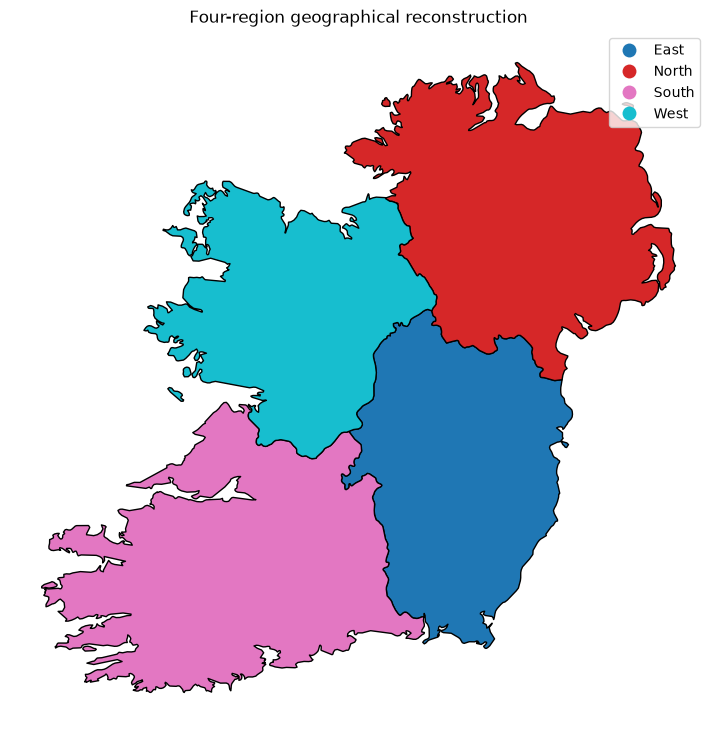

In [64]:
# Plot the four dissolved regions.
ax = regions_gdf.plot(
    column="model_region",
    categorical=True,
    legend=True,
    figsize=(9, 9),
    edgecolor="black"
)

# Add a title and remove unnecessary axis labels.
ax.set_title("Four-region geographical reconstruction")
ax.set_axis_off()

In [65]:
# Find GeoDataFrames currently defined in the notebook.
# This lets us reuse the grid-cell polygons we already constructed.
import geopandas as gpd

for variable_name, variable_value in list(globals().items()):
    if isinstance(variable_value, gpd.GeoDataFrame):
        print(
            f"{variable_name}: "
            f"{len(variable_value)} rows, "
            f"CRS = {variable_value.crs}"
        )

cells_gdf: 340 rows, CRS = EPSG:4326
cells_equal_area: 340 rows, CRS = EPSG:3035
land_cells: 159 rows, CRS = EPSG:4326
admin1: 4596 rows, CRS = EPSG:4326
ireland_admin1: 266 rows, CRS = EPSG:4326
northern_ireland: 26 rows, CRS = EPSG:4326
republic: 34 rows, CRS = EPSG:4326
island_admin1: 60 rows, CRS = EPSG:4326
province_units: 60 rows, CRS = EPSG:4326
provinces: 4 rows, CRS = EPSG:3035
grid_gdf: 340 rows, CRS = EPSG:3035
regional_units: 60 rows, CRS = EPSG:4326
regions_gdf: 4 rows, CRS = EPSG:3035


In [66]:
import geopandas as gpd
import numpy as np
import pandas as pd

# Keep only the region name and geometry from the regional GeoDataFrame.
region_boundaries = regions_gdf[["model_region", "geometry"]].copy()

# Intersect every grid cell with the regional boundaries.
# A cell crossing a regional boundary will produce multiple intersection rows.
cell_region_intersections = gpd.overlay(
    grid_gdf,
    region_boundaries,
    how="intersection"
)

# Calculate the area of each cell-region intersection in square metres.
cell_region_intersections["intersection_area_m2"] = (
    cell_region_intersections.geometry.area
)

# Remove any intersections with zero area.
cell_region_intersections = cell_region_intersections.loc[
    cell_region_intersections["intersection_area_m2"] > 0
].copy()

# Display the first few intersections.
print(cell_region_intersections[
    ["row", "col", "model_region", "intersection_area_m2"]
].head())

# Count how many cell-region intersections belong to each region.
print(cell_region_intersections.groupby("model_region").size())

   row  col model_region  intersection_area_m2
0    2   10        North          1.919423e+06
1    2   11        North          4.567570e+07
2    2   12        North          1.168820e+08
3    2   13        North          5.046895e+04
4    2   15        North          1.249095e+07
model_region
East     43
North    51
South    57
West     46
dtype: int64


In [67]:
# Define the order in which we want to store the four regions.
region_order = ["North", "East", "South", "West"]

# Retrieve the complete capacity-factor array.
# Its dimensions are (time, y, x).
capacity_factor_array = ds["capacity_factor"].values

# Create a dictionary to store each regional time series.
regional_capacity_factors = {}

# Process one region at a time.
for region in region_order:

    # Select the grid-cell intersections belonging to this region.
    region_cells = cell_region_intersections.loc[
        cell_region_intersections["model_region"] == region
    ]

    # Extract the grid row and column indices.
    rows = region_cells["row"].to_numpy(dtype=int)
    cols = region_cells["col"].to_numpy(dtype=int)

    # Extract the corresponding intersection areas.
    areas = region_cells["intersection_area_m2"].to_numpy()

    # Retrieve the capacity factors for these cells at every hour.
    # The resulting array has dimensions (time, number_of_intersections).
    cell_capacity_factors = capacity_factor_array[:, rows, cols]

    # Calculate the area-weighted regional capacity factor at each hour.
    regional_cf = np.average(
        cell_capacity_factors,
        axis=1,
        weights=areas
    )

    # Store the time series, retaining the original timestamps.
    regional_capacity_factors[region] = pd.Series(
        regional_cf,
        index=timestamps,
        name=region
    )

# Combine the four regional time series into one DataFrame.
regional_cf_df = pd.DataFrame(regional_capacity_factors)

# Display the first five hourly values.
print(regional_cf_df.head())

# Summarise the regional capacity-factor profiles.
print(regional_cf_df.describe())

                              North      East     South      West
2009-01-01 01:00:00+00:00  0.045401  0.124713  0.524174  0.222962
2009-01-01 02:00:00+00:00  0.057778  0.140332  0.599814  0.298052
2009-01-01 03:00:00+00:00  0.069611  0.146471  0.631738  0.353193
2009-01-01 04:00:00+00:00  0.069223  0.130708  0.602695  0.351488
2009-01-01 05:00:00+00:00  0.071837  0.119018  0.590311  0.347723
            North        East       South        West
count  744.000000  744.000000  744.000000  744.000000
mean     0.478008    0.449957    0.442179    0.489339
std      0.373191    0.365960    0.349206    0.354799
min      0.002050    0.000000    0.000000    0.000788
25%      0.106617    0.093056    0.117826    0.147373
50%      0.393367    0.375634    0.354528    0.461719
75%      0.872097    0.828837    0.770869    0.851325
max      1.000000    1.000000    1.000000    1.000000


In [68]:
# Ensure the regional shares follow the same order as the regional profiles.
regional_share = regional_share.reindex(region_order)

# Check that all four regional shares are available and sum to one.
assert regional_share.notna().all(), "A regional capacity share is missing."
assert np.isclose(regional_share.sum(), 1.0), "Regional shares do not sum to one."

# Calculate the national capacity factor at every hour.
national_cf = regional_cf_df.mul(regional_share, axis="columns").sum(axis=1)

# Give the resulting time series a descriptive name.
national_cf.name = "National_Capacity_Factor"

# Display the first five hourly values.
print(national_cf.head())

# Calculate summary statistics for January 2009.
print(national_cf.describe())

2009-01-01 01:00:00+00:00    0.216693
2009-01-01 02:00:00+00:00    0.256578
2009-01-01 03:00:00+00:00    0.279878
2009-01-01 04:00:00+00:00    0.269755
2009-01-01 05:00:00+00:00    0.266043
Name: National_Capacity_Factor, dtype: float64
count    744.000000
mean       0.466985
std        0.337284
min        0.010767
25%        0.151729
50%        0.416148
75%        0.771033
max        1.000000
Name: National_Capacity_Factor, dtype: float64


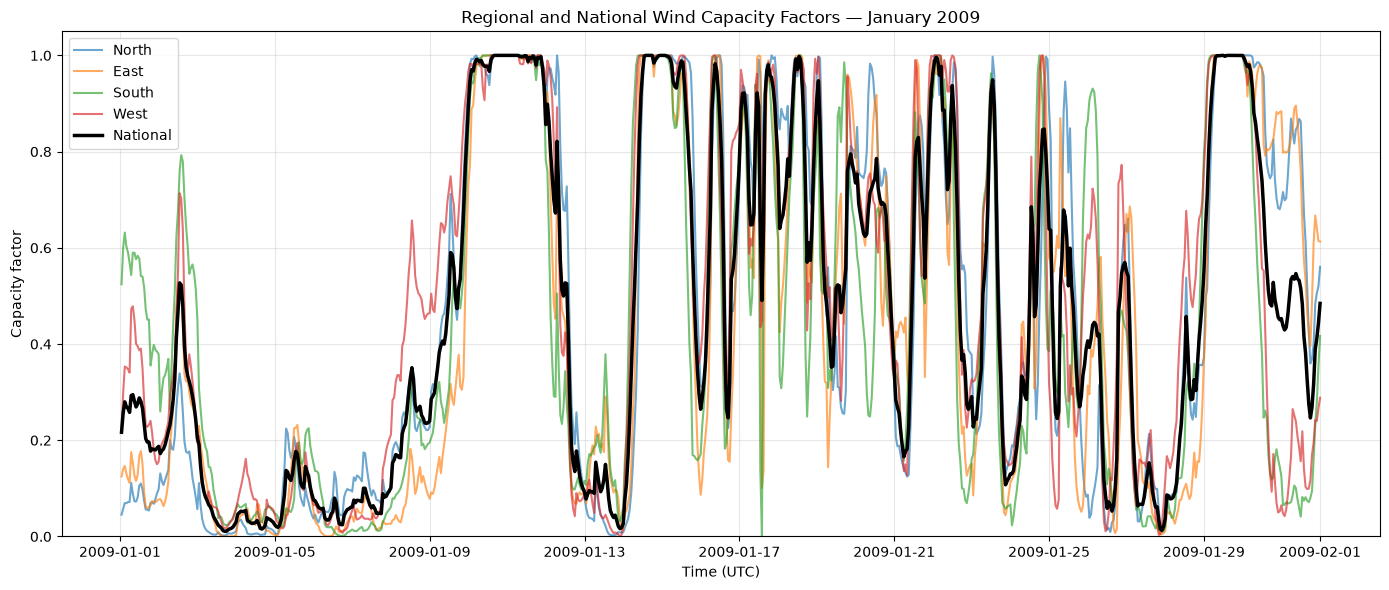

In [69]:
import matplotlib.pyplot as plt

# Create a figure for the regional and national capacity factors.
fig, ax = plt.subplots(figsize=(14, 6))

# Plot each regional capacity-factor time series.
for region in region_order:
    ax.plot(
        regional_cf_df.index,
        regional_cf_df[region],
        label=region,
        alpha=0.65
    )

# Plot the national capacity factor with a thicker line.
ax.plot(
    national_cf.index,
    national_cf,
    label="National",
    linewidth=2.5,
    color="black"
)

# Add axis labels, title and legend.
ax.set_xlabel("Time (UTC)")
ax.set_ylabel("Capacity factor")
ax.set_title("Regional and National Wind Capacity Factors — January 2009")
ax.set_ylim(0, 1.05)
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [70]:
# Independently calculate the national mean from the regional means.
national_mean_check = (
    regional_cf_df.mean() * regional_share
).sum()

# Compare it with the mean of the hourly national capacity-factor series.
print(f"National mean from hourly series: {national_cf.mean():.6f}")
print(f"National mean from regional means: {national_mean_check:.6f}")

# Calculate the absolute difference.
print(f"Absolute difference: {abs(national_cf.mean() - national_mean_check):.2e}")

National mean from hourly series: 0.466985
National mean from regional means: 0.466985
Absolute difference: 5.55e-17


In [71]:
# Sum the intersection areas belonging to each region.
covered_area = (
    cell_region_intersections
    .groupby("model_region")["intersection_area_m2"]
    .sum()
    .reindex(region_order)
)

# Calculate the full area of each regional polygon.
full_region_area = (
    regions_gdf.set_index("model_region")
    .geometry.area
    .reindex(region_order)
)

# Compare covered area with full regional area.
coverage_check = pd.DataFrame({
    "Covered_Area_km2": covered_area / 1e6,
    "Region_Area_km2": full_region_area / 1e6,
    "Coverage_Percent": 100 * covered_area / full_region_area
})

print(coverage_check)

              Covered_Area_km2  Region_Area_km2  Coverage_Percent
model_region                                                     
North             22995.536640     22995.536640             100.0
East              18962.095117     18962.095117             100.0
South             24147.075299     24147.075299             100.0
West              17591.629606     17591.629606             100.0
